In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, ConcatDataset
from torchvision import datasets
from torchvision.transforms import v2
import matplotlib.pyplot as plt
from datasets import load_dataset, Image

In [2]:
dataset = load_dataset("uoft-cs/cifar10")

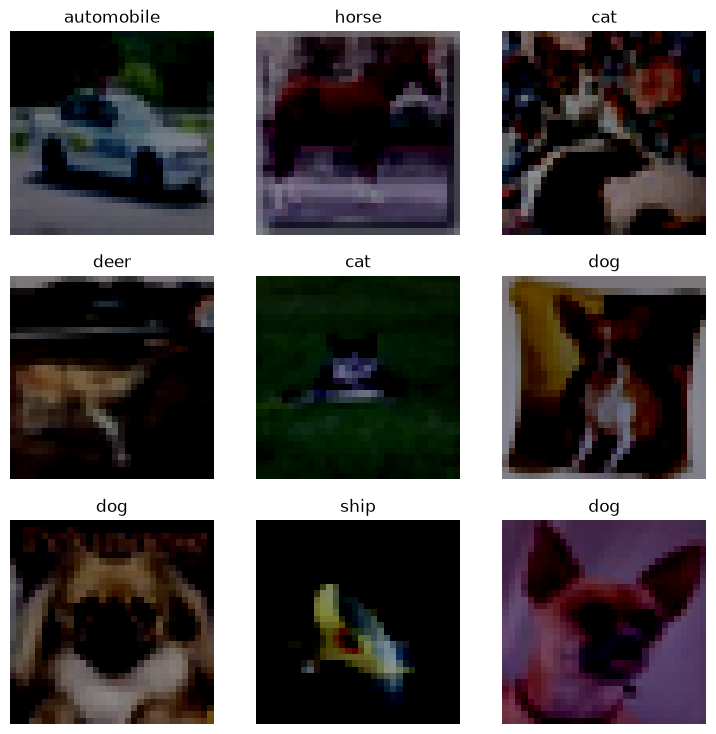

In [3]:
train_val = dataset["train"].train_test_split(test_size = 0.2, seed=111)

train = train_val["train"]
val = train_val["test"]
test = dataset["test"]

transforms = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
])

# Calculate per-pixel mean following the paper
pixel_sum = torch.zeros(3, 32, 32)
count = 0

for batch in train.iter(batch_size=256):
    imgs = torch.stack([transforms(img) for img in batch["img"]])
    pixel_sum += imgs.sum(dim=0)
    count += imgs.shape[0]

pixel_mean = pixel_sum / count

# Update transforms with normalization
transforms = v2.Compose([
    *transforms.transforms,
    v2.Lambda(lambda img: img - pixel_mean),
])

# Apply Necessary Transforms (including normalization haha)
def apply_transforms(examples):
    examples["img"] = [transforms(img) for img in examples["img"]]
    return examples

train = train.with_transform(apply_transforms)
val = val.with_transform(apply_transforms)
test = test.with_transform(apply_transforms)

# HuggingFace datasets preserve the class-index order btw btw btw btw btw
labels_map = dict(enumerate(train.features["label"].names))
classes = len(labels_map)

figure = plt.figure(figsize=(9, 9))
cols, rows = 3, 3

for i in range(1, cols * rows + 1):
    idx = i - 1
    img = train[i]["img"]
    label = train[i]["label"]
    figure.add_subplot(rows, cols, i),
    plt.title(labels_map[label]),
    plt.axis("off"),
    plt.imshow(img.permute(1, 2, 0).clamp(min=0, max=1)),

plt.show()

In [37]:

import math
def conv_out_size(
    in_size, in_channels, 
    out_channels, 
    kernel_size, 
    stride=1, 
    padding=0, 
    dilation=1, 
):
    h_in = in_size[0]
    w_in = in_size[1]
    
    h_out = math.floor((h_in + 2 * padding - dilation  * (kernel_size[0] - 1) - 1) / (stride) + 1) 
    w_out = math.floor((w_in + 2 * padding - dilation  * (kernel_size[1] - 1) - 1) / (stride) + 1)
    return (h_out, w_out)

cvos = conv_out_size

In [36]:
torch.manual_seed(42)
t = torch.randn((64, 16, 1, 1))

x = t.flatten(start_dim=1)
t[0][0]

tensor([[1.9269]])

In [44]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class ResidualBlock(nn.Module):
    def __init__(
        self, 
        in_channels, 
        out_channels, 
        stride=1,
        append=True
    ):
        super().__init__()

        # Only first layer takes in conv; downscaling if necessary
        self.conv1 = nn.Conv2d(
            in_channels, out_channels, 3,
            stride=stride, padding=1, bias=False
        ) 
        self.bn1 = nn.BatchNorm2d(out_channels)

        # Retain feature map dimensions (H, W).
        # Padding should be 1 by the previous formula
        self.conv2 = nn.Conv2d(
            out_channels, out_channels, 3,
            padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels)

        self.stride = stride
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.append = append

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        identity = x

        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))

        # Following the spirit of the ResNet paper, option A
        if self.stride != 1 or self.in_channels != self.out_channels:
            identity = identity[:, :, ::self.stride, ::self.stride]

            channel_diff = self.out_channels - self.in_channels
            
            if self.append:
                identity = F.pad(
                    identity,
                    (0, 0, 0, 0, 0, channel_diff)
                )
            else:
                left = channel_diff // 2
                right = channel_diff - left

                identity = F.pad(
                    identity,
                    (0, 0, 0, 0, left, right)
                )
                
        return F.relu(out + identity)
    

# Default: ResNet with 3 residual blocks per stage
# This means 20 layers
class ResNet(nn.Module):
    def __init__(self, n=3):
        super().__init__()
        
        self.conv1 = nn.Conv2d(3, 16, 3, padding=1, bias=False) # output shape: (N, 16, 32, 32)
        self.bn1 = nn.BatchNorm2d(16)

        # 32x32 feature maps w/ 16 output channels (filter)
        self.stage1 = nn.Sequential(
            *[ResidualBlock(16, 16) for _ in range(n)]
        )

        # 16x16 feature maps w/ 32 output channels (filters)
        self.stage2 = nn.Sequential(
            ResidualBlock(16, 32, stride=2),
            *[ResidualBlock(32, 32) for _ in range(n - 1)]
        )

        # 8x8 feature maps with 64 output channels (FILTERS)
        self.stage3 = nn.Sequential(
            ResidualBlock(32, 64, stride=2),
            *[ResidualBlock(32, 32) for _ in range(n - 1)]
        )

        
        self.pool = nn.AvgPool2d(8) # output shape (N, 64, 1, 1)
                                    # AdaptiveAvgPool2d would work too
        self.fc = nn.Linear(64, 10)
        
    def forward(x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.pool(x).flatten(start_dim=1)
        return self.fc(x)

In [45]:
batch_size = 64
    
train_dataloader = DataLoader(train.with_format("torch"), batch_size=batch_size)
val_dataloader = DataLoader(val.with_format("torch"), batch_size=batch_size)
test_dataloader = DataLoader(test.with_format("torch"), batch_size=batch_size)

In [46]:
criterion = nn.CrossEntropyLoss()
model = ResNet().to(device)
optimizer = optim.SGD(
    [p for p in model.parameters()],
    lr = 0.1,
    momentum=0.9,
    decay=0.0001
)

# Check for shapes
for batch in train_dataloader:
    X = batch["img"]
    y = batch["label"]

    logits = model(X)
    print(X.shape, y.shape, logits.shape)
    break

NameError: name 'device' is not defined

In [ ]:


num_epochs = 10
it = 0

for epoch in range(num_epochs):
    # Training
    model.train()
    train_loss = 0.0

    for images, labels in train_loader:
        it += 1
        
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

        if it == 32_000:
            optim.lr /= 10

        if it = 48_000:
            optim.lr /= 10

    # Loss for this epoch
    train_loss /= len(train_data)

    # Validation
    model.eval()
    valid_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in valid_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            valid_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

    valid_loss /= total
    accuracy = correct / total

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Valid Loss: {valid_loss:.4f} | "
        f"Valid Accuracy: {accuracy:.2%}"
    )